In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("C:\Customer_Churn_Analysis\Data\WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [2]:
# Count customers by tenure
tenure_counts = df["tenure"].value_counts().sort_index()

print(tenure_counts)

0      11
1     613
2     238
3     200
4     176
     ... 
68    100
69     95
70    119
71    170
72    362
Name: tenure, Length: 73, dtype: int64


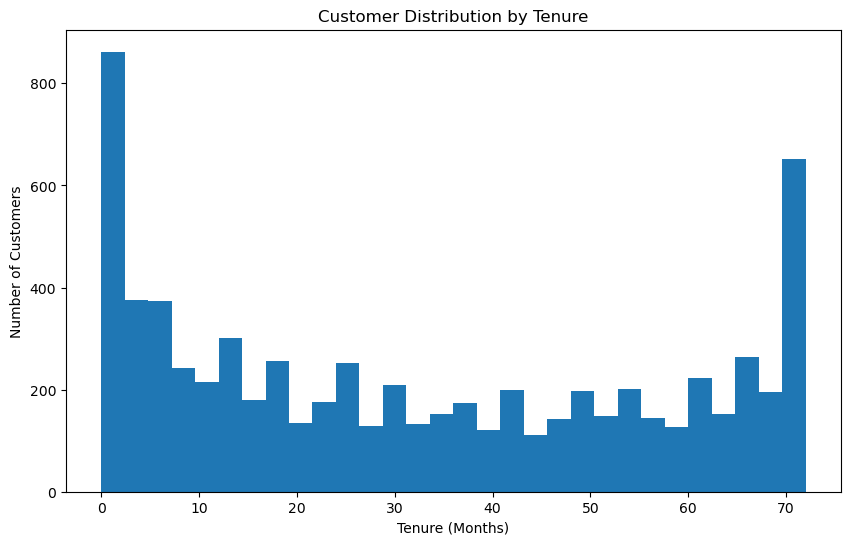

In [3]:

# Plot customer distribution by tenure
plt.figure(figsize=(10, 6))

plt.hist(
    df["tenure"],
    bins=30
)

plt.title("Customer Distribution by Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

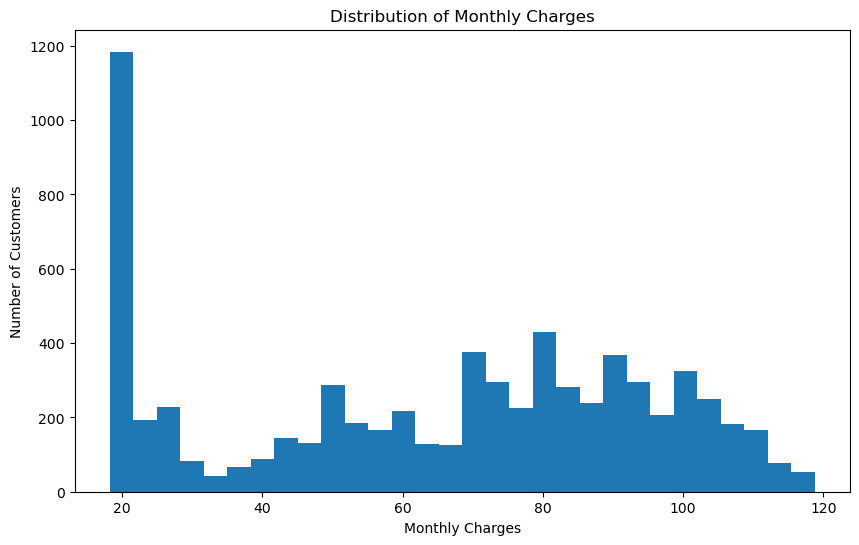

In [4]:
# Plot the distribution of monthly charges
plt.figure(figsize=(10, 6))

plt.hist(
    df["MonthlyCharges"],
    bins=30
)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.show()

<Figure size 1000x600 with 0 Axes>

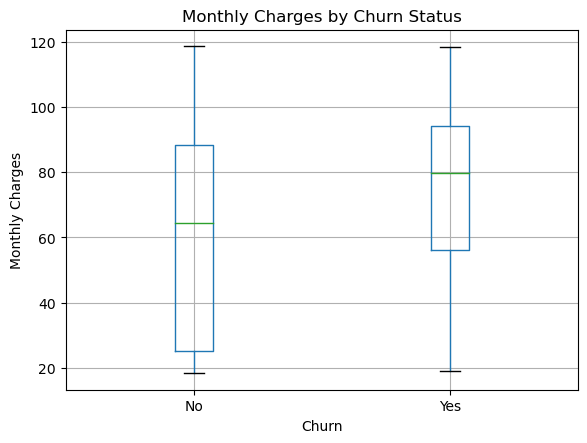

In [5]:
# Compare monthly charges by churn status
plt.figure(figsize=(10, 6))

df.boxplot(
    column="MonthlyCharges",
    by="Churn"
)

plt.title("Monthly Charges by Churn Status")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

### Monthly Charges and Churn

- Churned customers have a higher average monthly charge of 74.44 compared with 61.27 for retained customers.
- The median monthly charge is also higher among churned customers (79.65 vs 64.43).
- Higher monthly charges are associated with higher customer churn in this dataset.
- This is an association and does not prove that higher charges directly cause customers to churn.

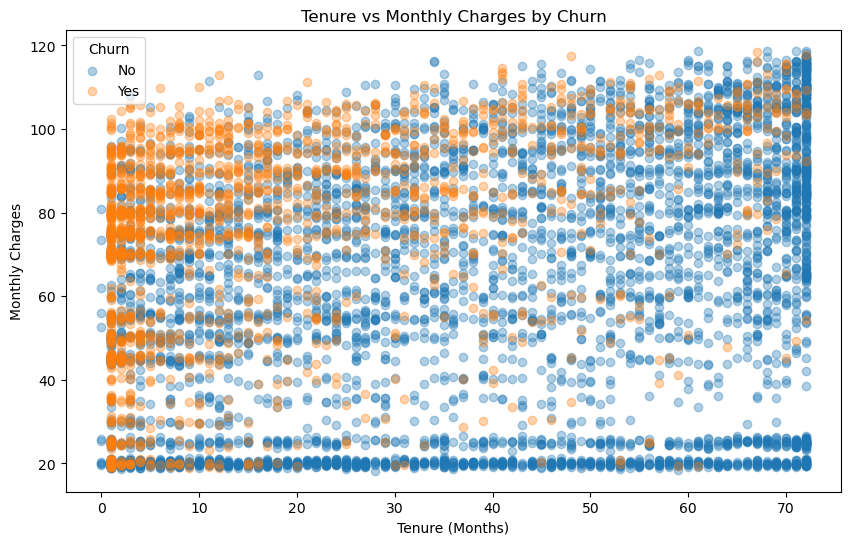

In [6]:
plt.figure(figsize=(10, 6))

for churn_status in ["No", "Yes"]:
    subset = df[df["Churn"] == churn_status]
    
    plt.scatter(
        subset["tenure"],
        subset["MonthlyCharges"],
        alpha=0.35,
        label=churn_status
    )

plt.title("Tenure vs Monthly Charges by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Monthly Charges")
plt.legend(title="Churn")
plt.show()

In [7]:
correlation = df[["tenure", "MonthlyCharges"]].corr()

print(correlation)

                tenure  MonthlyCharges
tenure          1.0000          0.2479
MonthlyCharges  0.2479          1.0000


### Tenure and Monthly Charges

- The correlation between tenure and monthly charges is 0.2479.
- This indicates a weak positive relationship between customer tenure and monthly charges.
- Customers with longer tenure tend to have slightly higher monthly charges, but the relationship is not strong.
- Other factors, such as internet service and additional services, may have a stronger influence on monthly charges.

In [8]:
churn_tenure = df.groupby("Churn")["tenure"].agg(
    ["count", "mean", "median", "min", "max"]
)

print(churn_tenure)

       count       mean  median  min  max
Churn                                    
No      5174  37.569965    38.0    0   72
Yes     1869  17.979133    10.0    1   72


### Tenure and Churn

- Customers who stayed have an average tenure of 37.57 months.
- Customers who churned have an average tenure of 17.98 months.
- The median tenure is 38 months for retained customers and 10 months for churned customers.
- Churned customers generally have shorter customer tenure than retained customers.
- This suggests that newer customers may be at higher risk of churn.
- This is an association in the dataset and does not prove that short tenure directly causes churn.

## Day 6 Findings

### Tenure Distribution
- Customer tenure ranges from 0 to 72 months.
- The dataset contains customers with both short and long tenure periods.
- There are 11 customers with a tenure of 0 months.

### Monthly Charges Distribution
- Monthly charges range from 18.25 to 118.75.
- Customers have a wide range of monthly charges.

### Monthly Charges and Churn
- Churned customers have a higher average monthly charge of 74.44 compared with 61.27 for retained customers.
- The median monthly charge is also higher among churned customers (79.65 vs 64.43).
- Higher monthly charges are associated with higher customer churn in this dataset.
- This association does not prove that higher charges directly cause customers to churn.

### Tenure and Monthly Charges
- The correlation between tenure and monthly charges is 0.2479.
- This indicates a weak positive relationship between tenure and monthly charges.
- Customers with longer tenure tend to have slightly higher monthly charges, but the relationship is not strong.

### Tenure and Churn
- Retained customers have an average tenure of 37.57 months.
- Churned customers have an average tenure of 17.98 months.
- The median tenure is 38 months for retained customers and 10 months for churned customers.
- Churned customers generally have shorter tenure than retained customers.
- This suggests that newer customers may be at higher risk of churn.

### Overall Day 6 Insight
- Tenure and monthly charges provide important numerical insights into customer churn.
- Churned customers tend to have shorter tenure and higher monthly charges.
- The relationship between tenure and monthly charges is weakly positive.
- These findings represent associations in the dataset and do not prove causation.